# Transformer NER — EDA

Kaggle: enable `KAGGLE_API_TOKEN` in Colab Secrets.

## 1. Setup

In [6]:
%pip -q install "kaggle>=1.7,<2" "transformers>=4.48,<5" sentencepiece protobuf tiktoken

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [7]:
import os
import ast
import re
import string
import subprocess
import zipfile
from pathlib import Path
from collections import Counter
from itertools import combinations

import numpy as np
import pandas as pd
from IPython.display import display
from transformers import AutoTokenizer

SEED = 42
COMPETITION = 'kse-ua-location-extraction-2026'
DATA_DIR = Path('/content/transformer_ner/data')
DATA_DIR.mkdir(parents=True, exist_ok=True)
AUDIT_N = 20_000
TOKENIZER_N = 2_000
LENGTHS = [64, 128, 256, 384, 512]

FILES = {'uk': 'uk_geo_dataset.csv', 'ru': 'ru_geo_dataset.csv',
         'lab': 'labeling_sample.csv', 'test': 'test.csv'}
MARKERS = ['loc_markers', 'org_markers', 'per_markers']
RESULTS = {}

def show(name, frame):
    RESULTS[name] = frame.copy()
    display(frame.round(3))

def sample(df, size):
    return df.sample(min(size, len(df)), random_state=SEED).reset_index(drop=True)

In [8]:
if not all(list(DATA_DIR.rglob(f)) for f in FILES.values()):
    from google.colab import userdata
    try:
        token = userdata.get('KAGGLE_API_TOKEN')
    except Exception as e:
        raise RuntimeError('Add KAGGLE_API_TOKEN to Colab Secrets and grant access.') from e
    os.environ['KAGGLE_API_TOKEN'] = token
    del token
    subprocess.run(['kaggle', 'competitions', 'download', '-c', COMPETITION,
                    '-p', str(DATA_DIR)], check=True)
    for archive in DATA_DIR.glob('*.zip'):
        with zipfile.ZipFile(archive) as z:
            z.extractall(DATA_DIR)

paths = {}
for name, filename in FILES.items():
    matches = list(DATA_DIR.rglob(filename))
    if len(matches) != 1:
        raise RuntimeError(f'Expected exactly one {filename}; found {matches}. Check competition files.')
    paths[name] = matches[0]

schema = {name: pd.read_csv(path, nrows=0).columns.tolist()
          for name, path in paths.items()}
show('schema', pd.DataFrame([{'dataset': k, 'file': FILES[k], 'columns': ', '.join(v)}
                             for k, v in schema.items()]))

required = {'uk': ['text', 'is_valid', *MARKERS], 'ru': ['text', *MARKERS],
            'lab': ['text', 'loc_markers'], 'test': ['text']}
for name, cols in required.items():
    missing = set(cols) - set(schema[name])
    if missing:
        raise ValueError(f'{name}: missing columns {missing}. Adapt to the actual Lab 4 schema.')

data = {name: pd.read_csv(path, usecols=[c for c in schema[name]
        if c in ['text', 'is_valid', *MARKERS, 'locations']], low_memory=False)
        for name, path in paths.items()}
flags = pd.to_numeric(data['uk']['is_valid'], errors='coerce')
assert flags.isin([0, 1]).all(), 'Unexpected is_valid values'
frames = {'uk_train': data['uk'].loc[flags.eq(0)],
          'uk_valid': data['uk'].loc[flags.eq(1)],
          'ru': data['ru'], 'lab': data['lab'], 'test': data['test']}
show('sizes', pd.DataFrame([{'dataset': k, 'rows': len(v)} for k, v in frames.items()]))

,dataset,file,columns
0,uk,uk_geo_dataset.csv,"text, loc_markers, org_markers, per_markers, i..."
1,ru,ru_geo_dataset.csv,"text, loc_markers, org_markers, per_markers, d..."
2,lab,labeling_sample.csv,"text, locations, loc_markers"
3,test,test.csv,"text_id, text, locations"


,dataset,rows
0,uk_train,1000000
1,uk_valid,10000
2,ru,8028840
3,lab,26
4,test,477


## 2. EDA

### 2.1. Dataset structure and target format

In [9]:
schema_rows, raw_examples = [], []
for name, path in paths.items():
    preview = pd.read_csv(path, nrows=3)
    for col in preview:
        nonnull = preview[col].dropna()
        schema_rows.append({'file': FILES[name], 'column': col,
                            'preview dtype': str(preview[col].dtype),
                            'example value': repr(nonnull.iloc[0])[:160] if len(nonnull) else None})
    for row in preview.head(2).to_dict('records'):
        raw_examples.append({'file': FILES[name], **row})
show('field_schema', pd.DataFrame(schema_rows))
with pd.option_context('display.max_colwidth', None):
    show('raw_examples', pd.DataFrame(raw_examples))

print('Test locations column (not ground truth):')
if 'locations' in frames['test']:
    print(frames['test'].locations.value_counts(dropna=False).head(10))
print('Available submission-related files:', [p.name for p in DATA_DIR.rglob('*.csv')
                                            if 'submission' in p.name.lower()])

,file,column,preview dtype,example value
0,uk_geo_dataset.csv,text,object,"'Чим довше мають скачки тиску гіпертензією, ти..."
1,uk_geo_dataset.csv,loc_markers,object,'[]'
2,uk_geo_dataset.csv,org_markers,object,'[]'
3,uk_geo_dataset.csv,per_markers,object,'[]'
4,uk_geo_dataset.csv,is_valid,int64,np.int64(0)
5,ru_geo_dataset.csv,text,object,'Вице-премьер по социальным вопросам Татьяна Г...
6,ru_geo_dataset.csv,loc_markers,object,"'[(82, 88)]'"
7,ru_geo_dataset.csv,org_markers,object,"'[(149, 160)]'"
8,ru_geo_dataset.csv,per_markers,object,"'[(36, 52)]'"
9,ru_geo_dataset.csv,doc_id,int64,np.int64(0)


,file,text,loc_markers,org_markers,per_markers,is_valid,doc_id,sent_id,locations,text_id
0,uk_geo_dataset.csv,"Чим довше мають скачки тиску гіпертензією, тим сильніше змінюються стінки цих судин.",[],[],[],0.0,NaN,NaN,NaN,NaN
1,uk_geo_dataset.csv,"А поки що починали цвісти троянди, випускники складали іспити, учні відпочивали в пришкільному таборі, а директор Володимир Хоботов марно оббивав пороги в пошуках транспорту.",[],[],"[(114, 131)]",0.0,NaN,NaN,NaN,NaN
2,ru_geo_dataset.csv,"Вице-премьер по социальным вопросам Татьяна Голикова рассказала, в каких регионах России зафиксирована наиболее высокая смертность от рака, сообщает РИА Новости.","[(82, 88)]","[(149, 160)]","[(36, 52)]",NaN,0.0,0.0,NaN,NaN
3,ru_geo_dataset.csv,"По словам Голиковой, чаще всего онкологические заболевания становились причиной смерти в Псковской, Тверской, Тульской и Орловской областях, а также в Севастополе.","[(89, 98), (100, 108), (110, 118), (121, 139), (151, 162)]",[],"[(10, 19)]",NaN,0.0,1.0,NaN,NaN
4,labeling_sample.csv,-261.310,[],NaN,NaN,NaN,NaN,NaN,[],NaN
5,labeling_sample.csv,"Проспект Бандери стоїть, як і пів міста… довго ще??\n\nЖиття🫶Оболонь","[(0, 16)]",NaN,NaN,NaN,NaN,NaN,['Проспект Бандери'],NaN
6,test.csv,"❗️Кількість поранених зросла до трьох, – Кличко\n\nКиїв — пряма трансляція 👈",NaN,NaN,NaN,NaN,NaN,NaN,[],0.0
7,test.csv,"🥤В Києві за 91,13 млн гривень починаються роботи зі знесення будівлі цеху №5 заводу “Більшовик”, які необхідні для продовження реконструкції “Шулявського шляхопроводу”.\n\n🤝Договір на проведення цих робіт КП ""Дирекція будівництва шляхово-транспортних споруд Києва"" уклало з ТОВ “Мостицький-2”, відхиливши вигіднішу пропозицію в тендері.\n\n🧐“Мостицький-2” відоме як постійний генпідрядник будівництва скандальних житлових комплексів Edelburg Development, яке пов'язують з сином екс-мера столиці Леоніда Черновецького Степаном👤. \n\nЦі компанії тісно сплетені бізнесовими та навіть родинними нитями👨‍👩‍👧‍👦.\n🧶Водночас зв'язки обраного для знесення цеху підрядника ведуть до ще однієї одіозної фігури - сумнозвісного столичного забудовника Максима Микитася, компанія з орбіти якого майже за 1,5 млрд гривень власне займається всією реконструкцією Шулявського шляхопроводу🏗",NaN,NaN,NaN,NaN,NaN,NaN,[],1.0


Test locations column (not ground truth):
locations
[]    477
Name: count, dtype: int64
Available submission-related files: []


**Conclusion:** The model receives raw text, while LOC, ORG and PER annotations are stored as character offsets. The competition requires location strings only; all 477 test target lists are empty placeholders. We will use token classification, reconstruct locations from the original text and retain `text_id` for submission.

### 2.2. Data quality and leakage

In [10]:
def usable_text(df):
    return df['text'].notna() & df['text'].astype('string').str.strip().ne('').fillna(False)

quality, hashes = [], {}
for name, df in frames.items():
    valid = usable_text(df)
    texts = df.loc[valid, 'text'].astype(str)
    h = pd.util.hash_pandas_object(texts, index=False).to_numpy()
    hashes[name] = np.unique(h)
    row = {'dataset': name, 'rows': len(df), 'missing_text': df.text.isna().sum(),
           'blank_text': (~valid & df.text.notna()).sum(),
           'duplicate_nonempty_rows': len(h) - len(hashes[name])}
    for col in MARKERS:
        row[f'{col}_missing'] = df[col].isna().sum() if col in df else np.nan
    quality.append(row)
show('quality', pd.DataFrame(quality))

pairs = []
for a, b in combinations(hashes, 2):
    common = len(np.intersect1d(hashes[a], hashes[b], assume_unique=True))
    pairs.append({'split_A': a, 'split_B': b, 'shared_unique_texts': common,
                  '% of B unique texts': 100 * common / max(1, len(hashes[b]))})
show('split_overlap', pd.DataFrame(pairs))

,dataset,rows,missing_text,blank_text,duplicate_nonempty_rows,loc_markers_missing,org_markers_missing,per_markers_missing
0,uk_train,1000000,0,0,2402,0.0,0.0,0.0
1,uk_valid,10000,0,0,0,0.0,0.0,0.0
2,ru,8028840,0,0,523501,0.0,0.0,0.0
3,lab,26,0,0,0,0.0,NaN,NaN
4,test,477,0,0,0,NaN,NaN,NaN


,split_A,split_B,shared_unique_texts,% of B unique texts
0,uk_train,uk_valid,52,0.52
1,uk_train,ru,0,0.00
2,uk_train,lab,0,0.00
3,uk_train,test,0,0.00
4,uk_valid,ru,0,0.00
5,uk_valid,lab,0,0.00
6,uk_valid,test,0,0.00
7,ru,lab,0,0.00
8,ru,test,0,0.00
9,lab,test,0,0.00


**Conclusion:** No missing or blank texts and no exact training–test overlaps were found. Ukrainian and Russian training contain 2,402 and 523,501 duplicate rows, respectively. Deduplicate after checking annotation conflicts and exclude the 52 shared Ukrainian training–validation texts from training to prevent leakage.

### 2.3. Annotation integrity, target balance and entity structure

Sample: `AUDIT_N` per split. Missing labels are not negatives.

In [11]:
def parse_spans(value, text):
    if value is None or (not isinstance(value, (list, tuple)) and pd.isna(value)):
        return None, 'missing'
    try:
        items = ast.literal_eval(value) if isinstance(value, str) else value
        if not isinstance(items, (list, tuple)):
            raise ValueError('not a list')
        spans = []
        for item in items:
            if not isinstance(item, (list, tuple)) or len(item) != 2:
                raise ValueError('invalid span shape')
            l, r = item
            if not isinstance(l, (int, np.integer)) or not isinstance(r, (int, np.integer)):
                raise ValueError('noninteger span')
            if not 0 <= l < r <= len(text) or not text[l:r].strip():
                raise ValueError('invalid bounds or blank span')
            spans.append((int(l), int(r)))
        return sorted(spans), 'ok'
    except (ValueError, TypeError, SyntaxError):
        return None, 'invalid'

samples = {k: sample(v.loc[usable_text(v)], AUDIT_N) for k, v in frames.items()}
WORD_RE = re.compile(r"\w+(?:['’ʼ-]\w+)*|[^\w\s]")

for name, df in samples.items():
    for col in MARKERS:
        if col in df:
            parsed = [parse_spans(v, t) for v, t in zip(df[col], df.text)]
            df[col + '_spans'] = [p[0] for p in parsed]
            df[col + '_status'] = [p[1] for p in parsed]

show('sample_sizes', pd.DataFrame([{'dataset': k, 'sample_rows': len(v)} for k,v in samples.items()]))

,dataset,sample_rows
0,uk_train,20000
1,uk_valid,10000
2,ru,20000
3,lab,26
4,test,477


In [12]:
target_rows, structure_rows, conflicts = [], [], []
for name, df in samples.items():
    for col in MARKERS:
        if col + '_spans' not in df:
            continue
        ok = df[df[col + '_status'].eq('ok')]
        counts = ok[col + '_spans'].map(len)
        strings = [text[l:r] for text, spans in zip(ok.text, ok[col + '_spans']) for l,r in spans]
        word_count, entity_word_count = 0, 0
        for text, spans in zip(ok.text, ok[col + '_spans']):
            words = [(m.start(), m.end()) for m in WORD_RE.finditer(text)]
            word_count += len(words)
            entity_word_count += sum(any(l < b and r > a for l,r in spans) for a,b in words)
        target_rows.append({'dataset': name, 'entity': col.split('_')[0].upper(),
            'valid_rows': len(ok), 'missing': df[col + '_status'].eq('missing').sum(),
            'invalid': df[col + '_status'].eq('invalid').sum(), 'mentions': counts.sum(),
            '% no entity': 100 * counts.eq(0).mean(), 'entities/text': counts.mean(),
            '% word-like tokens covered': 100 * entity_word_count / max(1, word_count)})
        multi = [len(s.split()) > 1 for s in strings]
        structure_rows.append({'dataset': name, 'entity': col.split('_')[0].upper(),
            '% multiword mentions': 100 * np.mean(multi) if strings else np.nan,
            'p95 chars/entity': np.percentile([len(s) for s in strings], 95) if strings else np.nan,
            '% rows repeated entity text': 100 * np.mean([
                len({text[l:r].casefold() for l,r in spans}) < len(spans)
                for text, spans in zip(ok.text, ok[col + '_spans'])]) if len(ok) else np.nan,
            '% rows overlapping same-type spans': 100 * np.mean([
                any(l2 < r1 for (l1,r1),(l2,r2) in zip(spans,spans[1:]))
                for spans in ok[col + '_spans']]) if len(ok) else np.nan})
    cols = [c + '_spans' for c in MARKERS if c + '_spans' in df]
    if len(cols) > 1:
        complete = df[df[cols].notna().all(axis=1)]
        overlaps = [any(l < b and r > a for x,y in combinations(row,2)
                       for l,r in x for a,b in y)
                    for row in complete[cols].itertuples(index=False, name=None)]
        conflicts.append({'dataset': name, 'fully_annotated_rows': len(complete),
                          '% cross-type overlap': 100*np.mean(overlaps) if overlaps else np.nan})
show('target_balance', pd.DataFrame(target_rows))
show('entity_structure', pd.DataFrame(structure_rows))
show('cross_type_overlap', pd.DataFrame(conflicts))

,dataset,entity,valid_rows,missing,invalid,mentions,% no entity,entities/text,% word-like tokens covered
0,uk_train,LOC,20000,0,0,6896,76.670,0.345,2.332
1,uk_train,ORG,20000,0,0,5418,79.875,0.271,2.884
2,uk_train,PER,20000,0,0,5660,78.340,0.283,2.496
3,uk_valid,LOC,10000,0,0,3304,76.970,0.330,2.243
4,uk_valid,ORG,10000,0,0,2792,79.370,0.279,2.985
5,uk_valid,PER,10000,0,0,2927,77.630,0.293,2.585
6,ru,LOC,20000,0,0,9135,69.050,0.457,2.666
7,ru,ORG,20000,0,0,10485,63.240,0.524,4.551
8,ru,PER,20000,0,0,7854,71.080,0.393,3.530
9,lab,LOC,26,0,0,32,38.462,1.231,3.396


,dataset,entity,% multiword mentions,p95 chars/entity,% rows repeated entity text,% rows overlapping same-type spans
0,uk_train,LOC,15.270,20.00,0.275,0.0
1,uk_train,ORG,42.949,36.00,0.175,0.0
2,uk_train,PER,50.035,19.00,0.060,0.0
3,uk_valid,LOC,15.073,20.00,0.280,0.0
4,uk_valid,ORG,44.305,36.45,0.130,0.0
5,uk_valid,PER,49.368,19.00,0.090,0.0
6,ru,LOC,12.173,18.00,0.380,0.0
7,ru,ORG,36.061,31.00,0.305,0.0
8,ru,PER,57.092,21.00,0.090,0.0
9,lab,LOC,28.125,21.00,0.000,0.0


,dataset,fully_annotated_rows,% cross-type overlap
0,uk_train,20000,0.045
1,uk_valid,10000,0.110
2,ru,20000,0.000


**Conclusion:** In the 20,000-text Ukrainian training sample, 76.67% of texts contain no LOC and only 2.33% of word-like tokens belong to locations. An all-negative classifier would achieve about 97.67% binary word-level accuracy, making accuracy misleading. Monitor entity-level F1, precision and recall; start with cross-entropy and test weighted loss if recall is low.

### 2.4. Target semantics and annotation examples

In [13]:
def parse_names(value):
    try:
        names = ast.literal_eval(value) if isinstance(value, str) else value
        return list(names) if isinstance(names, (list, tuple)) and all(isinstance(s, str) for s in names) else None
    except (ValueError, SyntaxError, TypeError):
        return None

manual_rows = []
for row in samples['lab'].itertuples(index=False):
    spans = row.loc_markers_spans
    names = parse_names(row.locations) if hasattr(row, 'locations') else None
    extracted = [row.text[l:r] for l, r in spans] if spans is not None else None
    manual_rows.append({'text': row.text, 'loc_markers': spans,
                        'extracted LOC': extracted, 'locations': names,
                        'same ordered list': names == extracted if names is not None and extracted is not None else None,
                        'same set': set(names) == set(extracted) if names is not None and extracted is not None else None})
manual = pd.DataFrame(manual_rows)
show('manual_target_agreement', pd.DataFrame([{
    'rows': len(manual), 'comparable rows': manual['same set'].notna().sum(),
    'exact list matches': manual['same ordered list'].eq(True).sum(),
    'exact set matches': manual['same set'].eq(True).sum()}]))
with pd.option_context('display.max_colwidth', None):
    show('manual_target_examples', manual)

,rows,comparable rows,exact list matches,exact set matches
0,26,26,26,26


,text,loc_markers,extracted LOC,locations,same ordered list,same set
0,"“Київський метрополітен” отримав ще 6 вагонів від варшавського метро\n\n🇵🇱Столичний метрополітен у серпні отримав другу партію, а загалом четверту партію варшавських вагонів – 6 одиниць рухомого складу. \n\n🚇Транспортування ще 24 вагонів (4 зчепи) триватиме до кінця 2023 року.",[],[],[],True,True
1,"❗️Буде більше придатних — Міноборони змінило наказ про ВЛК\n\nОновлено перелік хвороб для оцінки придатності військовослужбовців. Згідно з наказом №490 Міноборони:\n\nТепер за ""спірними"" статтями придатними будуть всі (йдеться про статті 2-в, 4-в, 5-в, 12-в, 13-в, 14-в, 17-в, 21-в, 22-в) ;\n\nОбмежено придатні будуть придатні за конкретним військовим фахом. Постанову прийматиме ВЛК.\n\nВимоги до здоров'я для десантників та морпіхів спростили: частина військових, які раніше визнавалися непридатними до служби у десанті, тепер будуть придатними до такої служби.\n\nНагадаємо, що РНБО під головуванням Президента розглянула роботу ВЛК та МСЕК, в результаті вирішили, що правоохоронці перевірять всіх громадян хто оформив інвалідність чи був «списаний» з військового обліку по здоров'ю після 24 лютого 2022 року.\n\nПідписатися | Запропонувати новину",[],[],[],True,True
2,-261.310,[],[],[],True,True
3,#афіша,[],[],[],True,True
4,"⛓️У Шевченківському районі оперативники затримали грабіжника, повідомляє поліція Києва.\n\nЗловмисник, вибравши жертву спровокував конфлікт, у ході якого побив чоловіка та заволодів його особистими речами – вирвав з рук сумку з грошима та документами.","[(4, 26)]",[Шевченківському районі],[Шевченківському районі],True,True
5,"В результате массированной атаки врага ночью в Фастовском и Бучанском районах возникли пожары и разрушения жилых домов, возгорание травяного настила\n\nВсе пожары успешно ликвидированы.\n\nПосле попадания обломков в один из домов ожоги получила 69-летняя женщина. Незначительные порезы также имеют 43-летний и 49-летний мужчины.","[(47, 57), (60, 69)]","[Фастовском, Бучанском]","[Фастовском, Бучанском]",True,True
6,У Київському національному університеті імені Тараса Шевченка ще 31 грудня 2022 року було пошкоджено модерністські вітражі. На сьогодні три із п’яти вже відновлено.,[],[],[],True,True
7,"Проспект Бандери стоїть, як і пів міста… довго ще??\n\nЖиття🫶Оболонь","[(0, 16)]",[Проспект Бандери],[Проспект Бандери],True,True
8,"🔥""Добро пожаловать в 24 февраля, товарищи"", — так події в Пскові коментують кацапи.\n\nБальзам на душу.\n\n@lossolomas_kyiv","[(58, 64)]",[Пскові],[Пскові],True,True
9,"Подовження роботи закладів харчування\n\nВладою Києва прийнято рішення щодо подовження роботи закладів харчування. Прошу виважено сприйняти це рішення. \n\nЦе не означає, що війна закінчилася і хтось дав зелене світло гучним гулянням. Користуйтеся із розумом та відповідальністю цією можливістю довше ввечері посидіти в кафе. \n\nЗакликаю киян і гостей міста пам’ятати, що поряд з вами сотні тисяч тих людей, які хвилюються за своїх рідних на фронті. Сотні і тисячі близьких, чиї рідні загинули. Тисячі тих, хто молиться за зцілення своїх поранених в госпіталях. Тому давайте будемо в цей час чуйними і адекватними. А ще давайте пам’ятати, що весь світ нам допомагає сьогодні. Тому ми маємо знати міру в відпочинку. \n\nМи будемо пильно стежити за дотриманням власниками і відвідувачами закладів усіх необхідних правил і законів. У разі виявлення системних порушень по Києву, ми готові скасувати це подовження роботи. \n\nТому - будьте свідомими. Не забувайте допомагати Збройним Силам України і таким чином наближати мир в Україні після нашої Перемоги, — Сергій Попко, начальник КМВА.\n\nПідписатися | Запропонувати новину","[(861, 866)]",[Києву],[Києву],True,True


In [14]:
def entity_context(text, l, r, width=55):
    return text[max(0, l-width):l] + ' ⟦' + text[l:r] + '⟧ ' + text[r:r+width]

cases = {
    'multiword': lambda s: len(s.split()) > 1,
    'digit': lambda s: any(c.isdigit() for c in s),
    'punctuation': lambda s: any(c in string.punctuation + '–—«»’ʼ' for c in s),
    'lowercase': lambda s: s.islower(),
    'outer whitespace': lambda s: s != s.strip(),
}
counts, examples, contexts = [], [], []
for name in ['uk_train', 'uk_valid', 'ru', 'lab']:
    df = samples[name]
    valid = df[df.loc_markers_status.eq('ok')]
    mentions = [(text, l, r) for text, spans in zip(valid.text, valid.loc_markers_spans) for l,r in spans]
    for case, predicate in cases.items():
        hits = [(t,l,r) for t,l,r in mentions if predicate(t[l:r])]
        counts.append({'dataset': name, 'case': case, 'mentions': len(hits),
                       '% LOC mentions': 100*len(hits)/max(1,len(mentions))})
        for t,l,r in hits[:2]:
            examples.append({'dataset': name, 'case': case, 'entity': repr(t[l:r]),
                             'offset': (l,r), 'context': entity_context(t,l,r)})
    for row in valid.itertuples(index=False):
        if len(contexts) and sum(x['dataset']==name for x in contexts) >= 3:
            break
        spans = row.loc_markers_spans
        if not spans:
            continue
        other = {c.split('_')[0].upper(): [row.text[l:r] for l,r in getattr(row,c+'_spans')]
                 for c in MARKERS[1:] if getattr(row,c+'_spans',None) is not None}
        if name != 'lab' and not any(other.values()):
            continue
        contexts.append({'dataset': name, 'text': row.text,
                         'LOC': [row.text[l:r] for l,r in spans], **other})
show('target_edge_cases', pd.DataFrame(counts).pivot(index='case', columns='dataset', values='% LOC mentions'))
with pd.option_context('display.max_colwidth', None):
    show('target_edge_examples', pd.DataFrame(examples))
    show('entity_type_examples', pd.DataFrame(contexts))

dataset,lab,ru,uk_train,uk_valid
case,,,,
digit,6.250,0.044,0.740,0.726
lowercase,0.000,0.055,0.435,0.515
multiword,28.125,12.173,15.270,15.073
outer whitespace,0.000,0.000,0.058,0.091
punctuation,6.250,4.652,4.800,4.328


,dataset,case,entity,offset,context
0,uk_train,multiword,'Городенківського району',"(97, 120)",ла правопорушення (ним виявився мешканець с. Незвисько ⟦Городенківського району⟧ ).
1,uk_train,multiword,'проспекті Миру',"(63, 77)","стався у дворі багатоповерхового житлового будинку на ⟦проспекті Миру⟧ , повідомили у відділі комунікації обласної поліції."
2,uk_train,digit,"'Кольцова, 18а'","(28, 41)","Інцидент стався на бульварі ⟦Кольцова, 18а⟧ , повідомляють вранці в четвер, 31 травня."
3,uk_train,digit,"'вулиці Вовчинецька, 2б'","(91, 113)","ити з 16 листопада у «Світі Сірків», що знаходиться на ⟦вулиці Вовчинецька, 2б⟧ ."
4,uk_train,punctuation,"'Кольцова, 18а'","(28, 41)","Інцидент стався на бульварі ⟦Кольцова, 18а⟧ , повідомляють вранці в четвер, 31 травня."
5,uk_train,punctuation,'-Франківської',"(100, 113)","переджають про можливість сходження лавин у горах Івано ⟦-Франківської⟧ , Чернівецької та Закарпатської областей."
6,uk_train,lowercase,'острові',"(11, 18)",У липні на ⟦острові⟧ Сардинія відбудеться саміт восьми світових лідерів.
7,uk_train,lowercase,'лісу',"(54, 58)",Дорослих і дітей чекаємо 14 вересня о 10.00 на «Святі ⟦лісу⟧ ».
8,uk_train,outer whitespace,'Червоній залі ',"(222, 236)","ія, можливості та виклики, яка розпочала свою роботу у ⟦Червоній залі ⟧ ЧНУ."
9,uk_train,outer whitespace,'Білого моря по ',"(72, 87)",пуск був проведений з підводного положення в акваторії ⟦Білого моря по ⟧ полігону «Кура» на Камчатці.


,dataset,text,LOC,ORG,PER
0,uk_train,Суд оголосив перше рішення щодо причетних до вибухів у Кропивницькому - Укрaїнa - TCH.,"[Кропивницькому, Укрaїнa]",[TCH],[]
1,uk_train,У Львівській області 15.09.2015 р. затверджено Регіональну Програму покращення медичної допомоги хворим з легеневою гіпертензією на 2015-2017 роки.,[Львівській області],[Регіональну Програму],[]
2,uk_train,А в додатковий час шайба капітана Донбасу Віктора Захарова принесла донеччанам першу перемогу в фіналі.,[Донбасу],[],[Віктора Захарова]
3,uk_valid,Президент Польщі Броніслав Коморовський вважає за необхідне надати Україні зброю.,"[Польщі, Україні]",[],[Броніслав Коморовський]
4,uk_valid,З метою недопущення скоєння злочинів СБУ видворила іноземця за межі держави та заборонила в'їзд в Україну.,[Україну],[СБУ],[]
5,uk_valid,"За словами Пугачова, головним покупцем жирів та олій українського виробництва традиційно, з 2015 року, виступає Індія - за дев'ять місяців цього року її частка в структурі українського експорту становила 31,3%.",[Індія],[],[Пугачова]
6,ru,"38-й президент США Джеральд Форд, скончавшийся 26 декабря на своем калифорнийском ранчо, был похоронен в среду вечером в городе Гранд-Рэпидс, штат Мичиган, на территории президентской мемориальной библиотеки-музея.","[США, Гранд-Рэпидс, Мичиган]",[],[Джеральд Форд]
7,ru,"Коновалов и его сообщник, Владислав Ковалев (оба являются жителями Витебска) были арестованы.",[Витебска],[],"[Коновалов, Владислав Ковалев]"
8,ru,"Как подчеркнул Ваммен, присоединение Дании к ЕвроПРО не связано с конфликтом на Украине и не направлено против России.","[Дании, Украине, России]",[ЕвроПРО],[Ваммен]
9,lab,"⛓️У Шевченківському районі оперативники затримали грабіжника, повідомляє поліція Києва.\n\nЗловмисник, вибравши жертву спровокував конфлікт, у ході якого побив чоловіка та заволодів його особистими речами – вирвав з рук сумку з грошима та документами.",[Шевченківському районі],NaN,NaN


In [15]:
ambiguous = []
for name in ['uk_valid','lab']:
    df = samples[name]
    valid = df[df.loc_markers_status.eq('ok')]
    known = {text[l:r].casefold() for text,spans in zip(valid.text,valid.loc_markers_spans)
             for l,r in spans if len(text[l:r].strip())>=3}
    for text, spans in zip(valid.text,valid.loc_markers_spans):
        for match in WORD_RE.finditer(text):
            l,r = match.span()
            if match.group().casefold() not in known or any(l<b and r>a for a,b in spans):
                continue
            ambiguous.append({'dataset':name,'name':match.group(),'context':entity_context(text,l,r)})
            if sum(x['dataset']==name for x in ambiguous)>=8:
                break
        if sum(x['dataset']==name for x in ambiguous)>=8:
            break
with pd.option_context('display.max_colwidth',None):
    show('unmarked_known_name_examples',pd.DataFrame(ambiguous, columns=['dataset','name','context']))
print('Unmarked examples require manual review: contextual ambiguity or missing annotations.')

,dataset,name,context
0,uk_valid,України,на Правил має бути приведена у відповідність до Закону ⟦України⟧ «Про охорону культурної спадщини» та відповідати прийн
1,uk_valid,НАТО,"Ми зрозуміли, що ми можемо бути членом ЄС, ⟦НАТО⟧ , але поки ти залежиш від одного джерела, не можеш бути"
2,uk_valid,Європи,"майбутнього бою ""Інтера"" і ""Шахтаря"" в 1/2 фіналу Ліги ⟦Європи⟧ ."
3,uk_valid,центр,"У Києві на території 2,6 га планують побудувати ⟦центр⟧ захисту тварин, що обійдеться місту в поточних цінах м"
4,uk_valid,місяці,Ще один вихідний день у цьому ⟦місяці⟧ - 9 травня.
5,uk_valid,Києва,Шевченківський суд ⟦Києва⟧ на 2 місяці взяв під варту без можливості застави Олек
6,uk_valid,місяці,Шевченківський суд Києва на 2 ⟦місяці⟧ взяв під варту без можливості застави Олексія Семенова
7,uk_valid,України,ункту 39.5.4 пункту 39.5 статті 39 Податкового кодексу ⟦України⟧ в разі застосування платником податків під час.
8,lab,Києва,"оперативники затримали грабіжника, повідомляє поліція ⟦Києва⟧ .\n\nЗловмисник, вибравши жертву спровокував конфлікт, у"
9,lab,Києва,Подовження роботи закладів харчування\n\nВладою ⟦Києва⟧ прийнято рішення щодо подовження роботи закладів харчу


Unmarked examples require manual review: contextual ambiguity or missing annotations.


**Conclusion:** All 26 manual target lists match their extracted character spans. Of the 32 manual location mentions, 28.13% are multiword, 6.25% contain digits and 6.25% contain punctuation. Preserve the original text, including case and address numbers, and use context to distinguish actual locations from channel signatures. Some gold spans cut through words, indicating possible annotation noise.

### 2.5. Distribution shift and additional training data

Script indicators are not language labels. Uses all available audit samples.

In [16]:
rows = []
for name, df in samples.items():
    t = df.text
    length = t.str.len()
    rows.append({'dataset': name, 'sample_rows': len(df), 'median chars': length.median(),
                 'p95 chars': length.quantile(.95),
                 '% URL': 100*t.str.contains(r'https?://|www\.', case=False, regex=True).mean(),
                 '% mentions/hashtags': 100*t.str.contains(r'[@#]\w+').mean(),
                 '% Latin letters': 100*t.str.contains(r'[a-zA-Z]').mean(),
                 '% UA-specific': 100*t.str.contains(r'[іїєґІЇЄҐ]').mean(),
                 '% RU-specific': 100*t.str.contains(r'[ыэъёЫЭЪЁ]').mean(),
                 '% both UA/RU indicators': 100*(t.str.contains(r'[іїєґІЇЄҐ]') &
                                               t.str.contains(r'[ыэъёЫЭЪЁ]')).mean()})
show('distribution_shift', pd.DataFrame(rows))

,dataset,sample_rows,median chars,p95 chars,% URL,% mentions/hashtags,% Latin letters,% UA-specific,% RU-specific,% both UA/RU indicators
0,uk_train,20000,91.0,199.0,0.035,0.000,6.420,98.765,0.100,0.100
1,uk_valid,10000,92.0,199.0,0.020,0.000,6.350,98.670,0.070,0.070
2,ru,20000,111.0,226.0,0.020,0.065,17.050,0.020,81.525,0.015
3,lab,26,217.5,814.0,0.000,11.538,23.077,92.308,3.846,0.000
4,test,477,264.0,1123.2,3.983,7.128,31.656,89.727,7.128,0.210


**Conclusion:** Median test text length is 264 characters versus 91 in Ukrainian training; URLs occur in 3.98% versus 0.035%, and Latin letters in 31.66% versus 6.42%. Ukrainian validation resembles training rather than test, so local F1 may not reflect leaderboard performance. Keep the 26 manual texts as a separate diagnostic set, not the sole validation set, and use overlapping windows for long inputs.

### 2.6. Entity novelty and normalization

Sampled training vocabulary; Lab 3 normalization (verify Lab 4 metric).

In [17]:
def normalize_location(text):
    text = re.sub(rf'[{re.escape(string.punctuation)}]', '', text)
    text = re.sub(r'\d', '', text)
    text = re.sub(r'\b\w\b\s?', '', text)
    return re.sub(r'\s+', ' ', text).strip().lower()

def location_lists(df):
    valid = df[df['loc_markers_status'].eq('ok')]
    return [[t[l:r] for l,r in spans] for t,spans in zip(valid.text,valid.loc_markers_spans)]

train_sets = {name: {s.casefold() for row in location_lists(samples[name]) for s in row}
              for name in ['uk_train', 'ru']}
train_hashes = np.union1d(hashes['uk_train'], hashes['ru'])
novelty = []
for name in ['uk_valid', 'lab']:
    df = samples[name]
    no_leak = ~np.isin(pd.util.hash_pandas_object(df.text.astype(str), index=False), train_hashes)
    entities = [s.casefold() for row in location_lists(df.loc[no_leak]) for s in row]
    for src, known in [('UK only', train_sets['uk_train']),
                       ('UK + RU', train_sets['uk_train'] | train_sets['ru'])]:
        novelty.append({'validation': name, 'training vocabulary': src,
            'mentions': len(entities), '% seen': 100*np.mean([s in known for s in entities]) if entities else np.nan,
            'unique validation names': len(set(entities))})
show('entity_novelty', pd.DataFrame(novelty))

norm_rows = []
for name in ['uk_train','uk_valid','ru','lab']:
    rows = location_lists(samples[name])
    raw = [s for row in rows for s in row]
    norm = [normalize_location(s) for s in raw]
    norm_rows.append({'dataset': name, 'mentions': len(raw),
        '% changed by normalization': 100*np.mean([a!=b for a,b in zip(raw,norm)]) if raw else np.nan,
        '% normalized empty': 100*np.mean([not s for s in norm]) if raw else np.nan,
        'unique raw names': len(set(raw)), 'unique normalized names': len(set(norm)),
        'within-text distinct names collapsed': sum(len(set(row))-len(set(map(normalize_location,row))) for row in rows)})
show('metric_normalization', pd.DataFrame(norm_rows))
examples = ['Київ', 'КИЇВ', 'вул. Шевченка 12', 'вул. Шевченка 18', 'Київська область', 'Київ']
show('normalization_examples', pd.DataFrame({'raw':examples,'normalized':list(map(normalize_location,examples))}))

,validation,training vocabulary,mentions,% seen,unique validation names
0,uk_valid,UK only,3293,71.029,1418
1,uk_valid,UK + RU,3293,72.062,1418
2,lab,UK only,32,34.375,30
3,lab,UK + RU,32,34.375,30


,dataset,mentions,% changed by normalization,% normalized empty,unique raw names,unique normalized names,within-text distinct names collapsed
0,uk_train,6896,99.623,0.406,2515,2473,2
1,uk_valid,3304,99.637,0.242,1424,1408,0
2,ru,9135,99.956,0.000,2772,2765,0
3,lab,32,100.000,0.000,30,30,0


,raw,normalized
0,Київ,київ
1,КИЇВ,київ
2,вул. Шевченка 12,вул шевченка
3,вул. Шевченка 18,вул шевченка
4,Київська область,київська область
5,Київ,київ


**Conclusion:** The sampled Ukrainian training vocabulary covers 71.03% of Ukrainian validation location mentions but only 34.38% of manual mentions. Adding sampled Russian data increases coverage to 72.06% and 34.38%, respectively. The model must generalize beyond memorized names; evaluate seen and unseen entities separately and test Russian data through an ablation. The previous metric’s normalization can collapse distinct addresses, but its applicability to this competition remains unverified.

### 2.7. Tokenizer comparison and entity coverage

Sample: `TOKENIZER_N` per split. Maximum length includes special tokens.

In [18]:
MODELS = {
    'mBERT': 'google-bert/bert-base-multilingual-cased',
    'XLM-R': 'FacebookAI/xlm-roberta-base',
    'mDeBERTa': 'microsoft/mdeberta-v3-base',
    'ruRoBERTa': 'ai-forever/ruRoberta-large',
    'EuroBERT': 'EuroBERT/EuroBERT-210m',
}

token_samples = {k: sample(df, TOKENIZER_N) for k,df in samples.items()}

def tokenizer_stats(tokenizer, df, model, dataset):
    lengths, total_words, unknown, total_tokens = [], 0, 0, 0
    entity_tokens, aligned, unmapped = [], 0, 0
    retained = Counter()
    special = tokenizer.num_special_tokens_to_add(pair=False)
    texts = df.text.tolist()
    spans_list = df['loc_markers_spans'].tolist() if 'loc_markers_spans' in df else [None]*len(df)
    for start in range(0,len(texts),64):
        batch = texts[start:start+64]
        enc = tokenizer(batch, add_special_tokens=False, truncation=False,
                        return_offsets_mapping=True, verbose=False)
        for text, spans, ids, offsets in zip(batch, spans_list[start:start+64],
                                             enc['input_ids'], enc['offset_mapping']):
            lengths.append(len(ids)+special)
            total_words += len(text.split())
            total_tokens += len(ids)
            if tokenizer.unk_token_id is not None:
                unknown += ids.count(tokenizer.unk_token_id)
            if spans is None:
                continue
            for l,r in spans:
                indices = [i for i,(a,b) in enumerate(offsets) if a < b and a < r and b > l]
                if not indices:
                    unmapped += 1
                    continue
                entity_tokens.append(len(indices))
                a = min(offsets[i][0] for i in indices)
                b = max(offsets[i][1] for i in indices)
                while a < b and text[a].isspace(): a += 1
                while b > a and text[b-1].isspace(): b -= 1
                ll, rr = l, r
                while ll < rr and text[ll].isspace(): ll += 1
                while rr > ll and text[rr-1].isspace(): rr -= 1
                aligned += (a == ll and b == rr)
                for limit in LENGTHS:
                    budget = limit-special
                    retained[limit, 'full'] += max(indices) < budget
                    retained[limit, 'partial'] += min(indices) < budget <= max(indices)
    lengths = np.array(lengths)
    n_entities = len(entity_tokens) + unmapped
    stats = {'model': model, 'dataset': dataset, 'texts': len(df),
             'tokens/whitespace word': total_tokens/max(1,total_words),
             '% unknown tokens': 100*unknown/max(1,total_tokens) if tokenizer.unk_token_id is not None else np.nan,
             'median tokens': np.median(lengths), 'p95 tokens': np.percentile(lengths,95),
             'locations': n_entities if dataset != 'test' else np.nan,
             'tokens/location': np.mean(entity_tokens) if entity_tokens else np.nan,
             '% exact boundary alignment': 100*aligned/n_entities if n_entities else np.nan,
             'unmapped locations': unmapped if dataset != 'test' else np.nan}
    coverage = [{'model': model, 'dataset': dataset, 'max_length': limit,
        '% full texts': 100*np.mean(lengths<=limit),
        '% full locations': 100*retained[limit,'full']/n_entities if n_entities else np.nan,
        '% partial locations': 100*retained[limit,'partial']/n_entities if n_entities else np.nan}
        for limit in LENGTHS]
    return stats, coverage

In [19]:
token_results, length_results, errors = [], [], []
for model, model_id in MODELS.items():
    print('Tokenizer:', model, flush=True)
    try:
        tokenizer = AutoTokenizer.from_pretrained(model_id, use_fast=True)
        if not tokenizer.is_fast:
            raise ValueError('Fast tokenizer unavailable; character offsets required')
        for name, df in token_samples.items():
            stats, coverage = tokenizer_stats(tokenizer, df, model, name)
            token_results.append(stats)
            length_results.extend(coverage)
    except Exception as e:
        errors.append({'model': model, 'error': str(e)[:500]})
        print(type(e).__name__, str(e)[:300])

show('tokenizers', pd.DataFrame(token_results))
show('tokenizer_errors', pd.DataFrame(errors, columns=['model','error']))
if not length_results:
    raise RuntimeError('No tokenizer completed. Review tokenizer_errors and rerun this cell.')
length_df = pd.DataFrame(length_results)
show('text_coverage', length_df.pivot(index=['model','dataset'], columns='max_length', values='% full texts'))
show('location_coverage', length_df[length_df.dataset.ne('test')].pivot(
    index=['model','dataset'], columns='max_length', values='% full locations'))
show('partial_location_coverage', length_df[length_df.dataset.ne('test')].pivot(
    index=['model','dataset'], columns='max_length', values='% partial locations'))

Tokenizer: mBERT


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

... (19 outputs left out)

,model,error


max_length             64       128      256      384      512
model     dataset                                             
EuroBERT  lab       46.154   69.231   88.462  100.000  100.000
          ru        90.950   99.900  100.000  100.000  100.000
          test      34.801   61.426   87.002   94.969   97.275
          uk_train  94.250  100.000  100.000  100.000  100.000
          uk_valid  94.950  100.000  100.000  100.000  100.000
XLM-R     lab       50.000   76.923   96.154  100.000  100.000
          ru        97.100  100.000  100.000  100.000  100.000
          test      45.283   72.327   91.405   96.855   98.323
          uk_train  98.650  100.000  100.000  100.000  100.000
          uk_valid  98.950  100.000  100.000  100.000  100.000
mBERT     lab       46.154   73.077   88.462  100.000  100.000
          ru        93.200   99.950  100.000  100.000  100.000
          test      38.574   63.941   88.050   95.388   97.484
          uk_train  93.250  100.000  100.000  100.000  100.000
          uk_valid  93.850  100.000  100.000  100.000  100.000
mDeBERTa  lab       46.154   73.077   92.308  100.000  100.000
          ru        93.800  100.000  100.000  100.000  100.000
          test      40.252   64.361   88.470   95.178   97.904
          uk_train  94.050  100.000  100.000  100.000  100.000
          uk_valid  94.250  100.000  100.000  100.000  100.000
ruRoBERTa lab       42.308   65.385   84.615   96.154  100.000
          ru        98.950  100.000  100.000  100.000  100.000
          test      31.027   56.184   81.551   92.034   95.597
          uk_train  88.900  100.000  100.000  100.000  100.000
          uk_valid  89.800  100.000  100.000  100.000  100.000

max_length             64       128      256    384    512
model     dataset                                         
EuroBERT  lab       65.625   96.875   96.875  100.0  100.0
          ru        96.242   99.896  100.000  100.0  100.0
          uk_train  96.429  100.000  100.000  100.0  100.0
          uk_valid  97.381  100.000  100.000  100.0  100.0
XLM-R     lab       81.250   96.875  100.000  100.0  100.0
          ru        98.643  100.000  100.000  100.0  100.0
          uk_train  99.224  100.000  100.000  100.0  100.0
          uk_valid  99.538  100.000  100.000  100.0  100.0
mBERT     lab       78.125   96.875   96.875  100.0  100.0
          ru        97.390   99.896  100.000  100.0  100.0
          uk_train  96.894  100.000  100.000  100.0  100.0
          uk_valid  97.535  100.000  100.000  100.0  100.0
mDeBERTa  lab       71.875   96.875   96.875  100.0  100.0
          ru        97.390  100.000  100.000  100.0  100.0
          uk_train  97.050  100.000  100.000  100.0  100.0
          uk_valid  98.151  100.000  100.000  100.0  100.0
ruRoBERTa lab       65.625   90.625   96.875  100.0  100.0
          ru        99.269  100.000  100.000  100.0  100.0
          uk_train  92.702  100.000  100.000  100.0  100.0
          uk_valid  95.223  100.000  100.000  100.0  100.0

max_length            64   128  256  384  512
model     dataset                            
EuroBERT  lab       3.125  0.0  0.0  0.0  0.0
          ru        0.731  0.0  0.0  0.0  0.0
          uk_train  1.087  0.0  0.0  0.0  0.0
          uk_valid  0.924  0.0  0.0  0.0  0.0
XLM-R     lab       6.250  0.0  0.0  0.0  0.0
          ru        0.104  0.0  0.0  0.0  0.0
          uk_train  0.311  0.0  0.0  0.0  0.0
          uk_valid  0.154  0.0  0.0  0.0  0.0
mBERT     lab       6.250  0.0  0.0  0.0  0.0
          ru        0.418  0.0  0.0  0.0  0.0
          uk_train  0.776  0.0  0.0  0.0  0.0
          uk_valid  0.924  0.0  0.0  0.0  0.0
mDeBERTa  lab       0.000  0.0  0.0  0.0  0.0
          ru        0.418  0.0  0.0  0.0  0.0
          uk_train  0.311  0.0  0.0  0.0  0.0
          uk_valid  0.000  0.0  0.0  0.0  0.0
ruRoBERTa lab       0.000  0.0  0.0  0.0  0.0
          ru        0.000  0.0  0.0  0.0  0.0
          uk_train  1.398  0.0  0.0  0.0  0.0
          uk_valid  0.924  0.0  0.0  0.0  0.0

**Conclusion:** Among five tokenizers, XLM-R produces the fewest tokens per word on test (1.97) and achieves 99.38% exact LOC boundary alignment on sampled Ukrainian training data. At 128 tokens, all sampled Ukrainian training locations are preserved, but only 72.33% of test texts fit; at 256 tokens, 91.41% fit. Start with XLM-R, 128-token training sequences and 256-token overlapping inference windows. Confirm encoder quality through validation F1.

### 2.8. Token labels and entity reconstruction

In [20]:
def encode_loc_tags(offsets, spans):
    tags = ['O'] * len(offsets)
    occupied = set()
    collisions = 0
    for l,r in spans:
        ids = [i for i,(a,b) in enumerate(offsets) if a < b and a < r and b > l]
        if occupied.intersection(ids):
            collisions += 1
            continue
        for j,i in enumerate(ids):
            tags[i] = 'B-LOC' if j == 0 else 'I-LOC'
        occupied.update(ids)
    return tags, collisions

In [21]:
def decode_loc_tags(offsets, tags):
    spans, active = [], None
    for (a,b),tag in zip(offsets,tags):
        if a >= b or tag == 'O':
            active = None
            continue
        if tag == 'B-LOC' or active is None:
            active = [a,b]
            spans.append(active)
        else:
            active[0], active[1] = min(active[0],a), max(active[1],b)
    return [tuple(s) for s in spans]

def trim_span(text, span):
    a,b = span
    while a < b and text[a].isspace(): a += 1
    while a < b and text[b-1].isspace(): b -= 1
    return (a,b)

xlmr = AutoTokenizer.from_pretrained(MODELS['XLM-R'], use_fast=True)
summaries, failures, token_example = [], [], None
for name in ['uk_train', 'uk_valid', 'ru', 'lab']:
    df = token_samples[name]
    df = df[df.loc_markers_status.eq('ok')]
    totals = {kind: Counter() for kind in ['BIO', 'binary']}
    for start in range(0,len(df),64):
        batch = df.iloc[start:start+64]
        enc = xlmr(batch.text.tolist(), add_special_tokens=False, truncation=False,
                   return_offsets_mapping=True, verbose=False)
        for text, spans, offsets, ids in zip(batch.text, batch.loc_markers_spans,
                                            enc.offset_mapping, enc.input_ids):
            tags, collisions = encode_loc_tags(offsets, spans)
            gold = set(spans)
            for kind, labels in [('BIO',tags), ('binary',['O' if t=='O' else 'I-LOC' for t in tags])]:
                pred = set(decode_loc_tags(offsets,labels))
                c = totals[kind]
                clean_gold = {trim_span(text, span) for span in gold}
                clean_pred = {trim_span(text, span) for span in pred}
                c.update({'trim_tp':len(clean_gold & clean_pred),
                          'trim_fp':len(clean_pred-clean_gold), 'trim_fn':len(clean_gold-clean_pred)})
                c.update({'tp':len(gold & pred), 'fp':len(pred-gold), 'fn':len(gold-pred),
                          'rows':1, 'exact_rows':int(gold==pred), 'token_collisions':collisions})
                if gold != pred and sum(x['dataset']==name and x['encoding']==kind for x in failures) < 2:
                    failures.append({'dataset':name,'encoding':kind,'text':text,
                                     'gold':[text[l:r] for l,r in sorted(gold)],
                                     'reconstructed':[text[l:r] for l,r in sorted(pred)]})
            if token_example is None and name=='lab' and any(' ' in text[l:r] for l,r in spans) and len(ids)<=200:
                token_example = pd.DataFrame({'token':xlmr.convert_ids_to_tokens(ids),
                                              'offset':offsets,'text':[text[a:b] for a,b in offsets],
                                              'BIO':tags,'binary':['O' if t=='O' else 'LOC' for t in tags]})
    for kind,c in totals.items():
        denom = 2*c['tp']+c['fp']+c['fn']
        trim_denom = 2*c['trim_tp']+c['trim_fp']+c['trim_fn']
        summaries.append({'dataset':name,'encoding':kind,'rows':c['rows'],
                          'gold spans':c['tp']+c['fn'],'missed spans':c['fn'],
                          'extra spans':c['fp'],'exact-span F1':2*c['tp']/denom if denom else np.nan,
                          'trimmed-span F1':2*c['trim_tp']/trim_denom if trim_denom else np.nan,
                          '% exact rows':100*c['exact_rows']/max(1,c['rows']),
                          'token collisions':c['token_collisions']})
show('label_roundtrip',pd.DataFrame(summaries))
if token_example is not None:
    show('token_label_example',token_example)
with pd.option_context('display.max_colwidth',None):
    show('label_roundtrip_failures',pd.DataFrame(failures))

,dataset,encoding,rows,gold spans,missed spans,extra spans,exact-span F1,trimmed-span F1,% exact rows,token collisions
0,uk_train,BIO,2000,644,4,4,0.994,0.994,99.800,0
1,uk_train,binary,2000,644,22,13,0.973,0.973,99.450,0
2,uk_valid,BIO,2000,649,5,5,0.992,0.994,99.750,0
3,uk_valid,binary,2000,649,32,17,0.962,0.963,99.150,0
4,ru,BIO,2000,958,0,0,1.000,1.000,100.000,0
5,ru,binary,2000,958,18,9,0.986,0.986,99.600,0
6,lab,BIO,26,32,1,1,0.969,0.969,96.154,0
7,lab,binary,26,32,1,1,0.969,0.969,96.154,0


,token,offset,text,BIO,binary
0,▁Ще,"(0, 2)",Ще,O,O
1,▁6,"(3, 4)",6,O,O
2,▁вар,"(5, 8)",вар,O,O
3,ша,"(8, 10)",ша,O,O
4,в,"(10, 11)",в,O,O
5,ських,"(11, 16)",ських,O,O
6,▁вагон,"(17, 22)",вагон,O,O
7,чи,"(22, 24)",чи,O,O
8,ків,"(24, 27)",ків,O,O
9,▁метро,"(28, 33)",метро,O,O


,dataset,encoding,text,gold,reconstructed
0,uk_train,BIO,"Дослідження провів обласний лабораторний центр Міністерства охорони здоров'я України. Згідно отриманих результатів, санітарно-хімічним показникам відповідають проби морської води лише з пляжів ""Отрада"" і ""Дельфін"".","[пляжів ""Отрада"" і ""Де]","[пляжів ""Отрада"" і ""Дель]"
1,uk_train,binary,"Дослідження провів обласний лабораторний центр Міністерства охорони здоров'я України. Згідно отриманих результатів, санітарно-хімічним показникам відповідають проби морської води лише з пляжів ""Отрада"" і ""Дельфін"".","[пляжів ""Отрада"" і ""Де]","[пляжів ""Отрада"" і ""Дель]"
2,uk_train,binary,"На стадії проектування і підготовки будівництва перебувають такі проекти як Північна об'їзна дорога Львова, Північна об'їзна Тернополя, Північна об'їзна Одеси, Східна об'їзна Кременчука з мостом через Дніпро.","[Північна об'їзна, Львова, Північна об'їзна, Тернополя, Північна об'їзна Одеси, Східна об'їзна, Кременчука, Дніпро]","[Північна об'їзна, Львова, Північна об'їзна Тернополя, Північна об'їзна Одеси, Східна об'їзна Кременчука, Дніпро]"
3,uk_train,BIO,"⚡ 1,5 тисячі громадян громадян України повернулися з Шарм-ель-Шейха.","[України, Шарм-ел, Шейха]","[України, Шарм-ель, Шейха]"
4,uk_valid,binary,Дендропарк розташований у селищі Копилів Макарівського району Київської області.,"[Копилів, Макарівського району, Київської області]",[Копилів Макарівського району Київської області]
5,uk_valid,BIO,"Детективи НАБУ під процесуальним керівництвом САП здійснюють низку обшуків в Одесі, зокрема, у будівлі, де розташовано ТРК ""Думська"" через можливі зловживання посадовцями Одеської облради.","[Одесі, ]","[Одесі,]"
6,uk_valid,binary,"Детективи НАБУ під процесуальним керівництвом САП здійснюють низку обшуків в Одесі, зокрема, у будівлі, де розташовано ТРК ""Думська"" через можливі зловживання посадовцями Одеської облради.","[Одесі, ]","[Одесі,]"
7,uk_valid,BIO,Станція розташована біля міста Енергодар Запорізької області поруч із Запорізькою АЕС.,[Енергодар Запорізької області пору],[Енергодар Запорізької області поруч]
8,ru,binary,"18 августа Пентагон разрешил выполнять полеты всем F-35, кроме самолетов первой мелкосерийной партии, приписанных к авиабазе ВВС США Эглин.","[США, Эглин]",[США Эглин]
9,ru,binary,"Cотрудники УМВД по Центральному району Санкт-Петербурга провели серию обысков на квартирах собственников компании «Интех», которая строила дата-центр «ВКонтакте» во Всеволожском районе Ленобласти в 2011-2012 годах.","[Центральному району, Санкт-Петербурга, Всеволожском районе, Ленобласти]","[Центральному району Санкт-Петербурга, Всеволожском районе Ленобласти]"


**Conclusion:** With perfect token labels, BIO achieves 0.992 exact-span reconstruction F1 on sampled Ukrainian validation versus 0.962 for binary encoding; both reach 0.969 on manual validation. Binary labels merge adjacent locations, while BIO preserves separate entity beginnings. Use BIO and reconstruct strings from tokenizer offsets; boundaries inside subwords can still cause errors. These scores measure reconstruction, not trained model performance.

### 2.9. Corpus structure and real examples

In [23]:
results = []

for name, df in samples.items():
    t = df.text
    lines = t.map(lambda x: [s.strip() for s in x.splitlines() if s.strip()])
    last = lines.map(lambda x: x[-1] if x else '')
    repeated = last.value_counts()
    repeated = repeated[repeated.gt(1)].index.difference([''])

    results.append({
        'dataset': name,
        'sample size': len(df),
        '% multiline': lines.map(len).gt(1).mean() * 100,
        '% paragraph breaks': t.str.contains(r'\n\s*\n').mean() * 100,
        '% digits': t.str.contains(r'\d').mean() * 100,
        '% uppercase words': t.str.contains(r'\b[А-ЯІЇЄҐA-Z]{3,}\b').mean() * 100,
        '% repeated last line': last.isin(repeated).mean() * 100
    })

display(pd.DataFrame(results).round(2))

for name in ['lab', 'test']:
    last = samples[name].text.map(
        lambda t: t.strip().split('\n')[-1].strip()
    )

    repeated = last.value_counts()
    repeated = repeated[repeated.gt(1)].head(3)

    print(f'\n{name}: most common repeated last lines')

    for text, count in repeated.items():
        print(f'{count}: {text[:150]}')

,dataset,sample size,% multiline,% paragraph breaks,% digits,% uppercase words,% repeated last line
0,uk_train,20000,0.00,0.00,21.50,10.56,0.02
1,uk_valid,10000,0.00,0.00,21.85,10.64,0.00
2,ru,20000,0.00,0.00,34.67,17.34,0.66
3,lab,26,80.77,80.77,57.69,19.23,26.92
4,test,477,85.12,81.34,58.49,31.24,38.57



lab: most common repeated last lines
3: Життя🫶Оболонь
2: Підписатися    |    Запропонувати новину
2: Надіслати новину

test: most common repeated last lines
29: ㅤ
24: Підписатись на Дарниця Livе
20: Хуйовий Київ | Надіслати новину


38.57% of test texts contain repeated final lines, often representing channel signatures that include geographical names, such as «Дарниця» or «Київ». These may lead to false-positive location predictions.

### 2.10. Document-level context

,dataset,doc_id,sent_id,text_id
0,uk,False,False,False
1,ru,True,True,False
2,lab,False,False,False
3,test,False,False,True


,rows,missing doc_id,missing sent_id,documents,% multi-sentence documents,% rows in multi-sentence documents,median sentences/doc,p95 sentences/doc,max sentences/doc,duplicate sentence IDs,documents with sentence ID gaps,nonincreasing sentence IDs
0,8028840,0,0,739190,99.69,99.971,10.0,18.0,686,0,75871,0


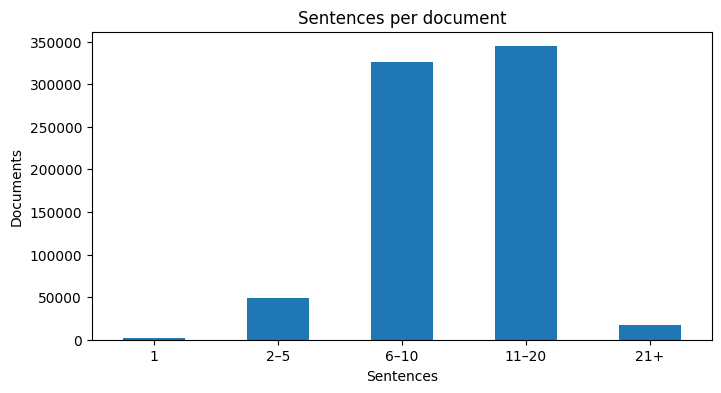

In [24]:
show('document_metadata', pd.DataFrame([
    {
        'dataset': k,
        'doc_id': 'doc_id' in cols,
        'sent_id': 'sent_id' in cols,
        'text_id': 'text_id' in cols
    }
    for k, cols in schema.items()
]))

doc_ids = pd.read_csv(
    paths['ru'],
    usecols=['doc_id', 'sent_id'],
    dtype={'doc_id': 'Int64', 'sent_id': 'Int64'}
)

assert doc_ids.index.equals(data['ru'].index)

valid_ids = doc_ids.dropna()

groups = valid_ids.groupby('doc_id', sort=False).sent_id.agg(
    ['size', 'nunique', 'min', 'max']
)

multi = groups['size'].gt(1)
unique_order = groups['size'].eq(groups['nunique'])

contiguous = (
    unique_order &
    groups['size'].eq(groups['max'] - groups['min'] + 1)
)

same_doc = doc_ids.doc_id.eq(doc_ids.doc_id.shift()).fillna(False)

nonincreasing = (
    same_doc &
    doc_ids.sent_id.le(doc_ids.sent_id.shift()).fillna(False)
)

show('document_structure', pd.DataFrame([{
    'rows': len(doc_ids),
    'missing doc_id': doc_ids.doc_id.isna().sum(),
    'missing sent_id': doc_ids.sent_id.isna().sum(),
    'documents': len(groups),
    '% multi-sentence documents': 100 * multi.mean(),
    '% rows in multi-sentence documents':
        100 * groups.loc[multi, 'size'].sum() / len(valid_ids),
    'median sentences/doc': groups['size'].median(),
    'p95 sentences/doc': groups['size'].quantile(.95),
    'max sentences/doc': groups['size'].max(),
    'duplicate sentence IDs': (~unique_order).sum(),
    'documents with sentence ID gaps': (unique_order & ~contiguous).sum(),
    'nonincreasing sentence IDs': nonincreasing.sum()
}]))

pd.cut(
    groups['size'],
    bins=[0, 1, 5, 10, 20, np.inf],
    labels=['1', '2–5', '6–10', '11–20', '21+']
).value_counts().sort_index().plot(
    kind='bar',
    figsize=(8, 4),
    title='Sentences per document',
    xlabel='Sentences',
    ylabel='Documents',
    rot=0
);

In [25]:
DOC_N = 400
MAX_DOC_ROWS = 100

eligible = groups.index[
    contiguous & multi & groups['size'].le(MAX_DOC_ROWS)
]

chosen = pd.Series(eligible).sample(
    min(DOC_N, len(eligible)), random_state=SEED
)

selected = (
    valid_ids.loc[valid_ids.doc_id.isin(chosen)]
    .join(data['ru'][['text', 'loc_markers']])
    .sort_values(['doc_id', 'sent_id'])
)

documents, examples = [], []
counts = Counter()

for doc_id, group in selected.groupby('doc_id', sort=False):
    if not usable_text(group).all():
        continue

    texts = group.text.tolist()

    parsed = [
        parse_spans(v, t)
        for v, t in zip(group.loc_markers, texts)
    ]

    if any(status != 'ok' for _, status in parsed):
        continue

    spans = [s for s, _ in parsed]

    names = [
        {t[a:b].casefold() for a, b in s}
        for t, s in zip(texts, spans)
    ]

    positive = sum(bool(s) for s in spans)
    seen = set()

    counts.update({
        'documents': 1,
        'sentences': len(texts),
        'positive documents': int(positive > 0),
        'positive sentences': positive,
        'sentences in positive docs': len(texts) if positive else 0,
        'negative sentences in positive docs':
            len(texts) - positive if positive else 0
    })

    for i, (text, s, current) in enumerate(zip(texts, spans, names)):
        if i > 0:
            counts['noninitial sentences'] += 1
            counts['previous sentence contains LOC'] += bool(names[i - 1])

        for a, b in s:
            counts['LOC mentions'] += 1
            counts['repeated LOC'] += text[a:b].casefold() in seen

        seen.update(current)

    documents.append((doc_id, texts, spans))

    if len(examples) < 5 and positive >= 2:
        examples.append({
            'doc_id': doc_id,
            'sentences': len(texts),
            'document': '\n'.join(
                f'{sid}: {t} | LOC: {[t[a:b] for a, b in s]}'
                for sid, t, s in zip(group.sent_id, texts, spans)
            )
        })

c = counts

show('document_context', pd.DataFrame([{
    'eligible documents': len(eligible),
    'sampled documents': len(chosen),
    'usable documents': c['documents'],
    'sentences': c['sentences'],
    '% documents containing LOC':
        100 * c['positive documents'] / max(1, c['documents']),
    '% sentences containing LOC':
        100 * c['positive sentences'] / max(1, c['sentences']),
    '% noninitial sentences with LOC in previous sentence':
        100 * c['previous sentence contains LOC'] /
        max(1, c['noninitial sentences']),
    '% repeated LOC from earlier sentences':
        100 * c['repeated LOC'] / max(1, c['LOC mentions']),
    '% negative sentences within positive documents':
        100 * c['negative sentences in positive docs'] /
        max(1, c['sentences in positive docs'])
}]))

with pd.option_context('display.max_colwidth', None):
    show('document_examples', pd.DataFrame(examples))

,eligible documents,sampled documents,usable documents,sentences,% documents containing LOC,% sentences containing LOC,% noninitial sentences with LOC in previous sentence,% repeated LOC from earlier sentences,% negative sentences within positive documents
0,661020,400,400,4544,91.75,31.448,31.491,26.146,65.748


,doc_id,sentences,document
0,2613,14,"0: Военное положение в регионах Украины, граничащих с Россией и Приднестровьем (Винницкой, Луганской, Николаевской, Одесской, Сумской, Харьковской, Черниговской, Херсонской, Донецкой и Запорожской областях, а также внутренних водах Азовско-Керченской акватории) вступит в силу одновременно с соответствующим законом. | LOC: ['Украины', 'Россией', 'Приднестровьем', 'Винницкой', 'Луганской', 'Николаевской', 'Одесской', 'Сумской', 'Харьковской', 'Черниговской', 'Херсонской', 'Донецкой', 'Запорожской областях', 'Азовско-Керченской акватории']\n1: Об этом во вторник, 27 ноября, заявил спикер Верховной Рады Андрей Парубий, передает «Интерфакс». | LOC: []\n2: «Хотя в самом указе [президента Украины Петра Порошенко] стоит дата 14:00 (15:00 мск) 26 [ноября], реально он начнет действовать тогда, когда будет подписан и опубликован. | LOC: ['Украины']\n3: Думаю, скорее всего, это будет завтра в течение дня», — указал он. | LOC: []\n4: Парубий добавил, что намерен подписать закон о введении военного положения по возвращении на Украину — в среду, 28 ноября. | LOC: ['Украину']\n5: После этого, надеется спикер Рады, документ оперативно подпишет Порошенко. | LOC: []\n6: После этого указ должен быть опубликован в «Урядовом курьере» — издании центральных органов исполнительной власти Украины. | LOC: ['Украины']\n7: «С той секунды закон, соответственно, и указ президента вступает в силу», — сказал Парубий. | LOC: []\n8: C этого момента и будет введено военное положение, отметил он. | LOC: []\n9: Днем 27 ноября президент Украины Петр Порошенко подписал указ, который вносит изменения в решение Совета национальной безопасности и обороны (СНБО) страны относительно продолжительности действия военного положения в стране. | LOC: ['Украины']\n10: В указе говорится, что военное положение начало действовать с 14:00 (15:00 мск) 26 ноября и должно закончиться в 14:00 (15:00 мск) 26 декабря. | LOC: []\n11: При этом в администрации президента сообщили, что военное положение будет введено с 14:00 (15:00 мск) 28 ноября. | LOC: []\n12: За введение в ряде областей страны военного положения 26 ноября проголосовали депутаты Верховной Рады. | LOC: []\n13: Планировалось, что положение начнет действовать с 9:00 (10:00 мск) 28 ноября. | LOC: []"
1,4442,12,"0: Премьер-министр Чехии Андрей Бабиш предложил восстановить гражданство писателю Милану Кундере. | LOC: ['Чехии']\n1: Об этом во вторник, 13 ноября, сообщает The Guardian. | LOC: []\n2: Бабиш встретился с прозаиком и его женой Верой в Париже на выходных. | LOC: ['Париже']\n3: По его словам, он побывал у них в квартире, после чего они три часа общались в любимом ресторане Кундеры. | LOC: []\n4: «Для меня это была огромная честь», — отметил политик, назвав писателя «легендой чешской, французской и мировой литературы». | LOC: []\n5: Бабиш подчеркнул, что диалог направляла супруга Кундеры, которую он описал как «невероятно энергичную леди». | LOC: []\n6: «Я считаю, что они заслуживают гражданство Чехии, которое они потеряли после эмиграции», — резюмировал премьер-министр. | LOC: ['Чехии']\n7: В 1979 власти Чехословацкой Социалистической Республики лишили гражданства Кундеру, который в 1975 году эмигрировал во Францию. | LOC: ['Чехословацкой Социалистической Республики', 'Францию']\n8: Спустя два года писатель получил французский паспорт. | LOC: []\n9: Литератор не был на территории Чехии 22 года. | LOC: ['Чехии']\n10: В библиографии Милана Кундеры — романы «Невыносимая легкость бытия», «Шутка», «Вальс на прощание», сборник новелл «Смешные любови» и эссе «Нарушенные завещания». | LOC: []\n11: Свои произведения писатель создает как на чешском, так и на французском языках. | LOC: []"
2,4756,10,"0: Товарооборот между Россией и Китаем по итогам 2018 года достигнет 110 миллиардов долларов, сообщил министр экономического развития Максим Орешкин в интервью «Известиям». | LOC: ['Россией', 'Китаем']\n1: «Поставленная на этот год цель в 100 миллиардов долларов точно будет превышена», — сказал Оре

In [27]:
def pct(a, b):
    return 100 * a / b if b else np.nan

display(pd.DataFrame([
    {
        'max length': limit,
        '% complete documents': pct(c['complete docs'], c['docs']),
        '% LOC without windows': pct(c['retained without windows'], c['entities']),
        '% LOC with windows': pct(c['retained with windows'], c['entities']),
        'sentence windows': c['sentence windows'],
        'document windows': c['document windows']
    }
    for limit, c in totals.items()
]).round(2))

,max length,% complete documents,% LOC without windows,% LOC with windows,sentence windows,document windows
0,128,2.00,40.79,100.0,4546,1923
1,256,27.00,70.17,100.0,4544,768
2,512,91.25,96.41,100.0,4544,436


**Conclusion**: The median document length is 319.5 tokens compared to 29 tokens per sentence. At a maximum sequence length of 256, only 27% of documents fit completely, and truncation would discard 29.83% of location entities. However, overlapping sliding windows preserve 100% of sampled entities at every tested sequence length.

Therefore, we should experiment with document-level training using doc_id and sent_id, combined with overlapping 256 or 512 token windows.

### 2.11. Column contents and annotation relationships

In [28]:
relationships = []

for name in ['uk_train', 'uk_valid', 'ru']:
    df = samples[name]

    valid = df[
        df[[c + '_status' for c in MARKERS]].eq('ok').all(axis=1)
    ]

    loc, org, per = [
        valid[c + '_spans'].map(bool) for c in MARKERS
    ]

    relationships.append({
        'dataset': name,
        'valid rows': len(valid),
        '% LOC only': (loc & ~org & ~per).mean() * 100,
        '% ORG/PER without LOC': (~loc & (org | per)).mean() * 100,
        '% LOC with ORG/PER': (loc & (org | per)).mean() * 100,
        '% no entities': (~loc & ~org & ~per).mean() * 100,
        '% ORG given LOC': org[loc].mean() * 100,
        '% PER given LOC': per[loc].mean() * 100
    })

display(pd.DataFrame(relationships).round(2))

for name, path in paths.items():
    df = pd.read_csv(path, nrows=500)
    df = df[df.text.notna() & df.text.str.len().le(250)].copy()

    if df.empty:
        continue

    cols = [c for c in MARKERS if c in df.columns]

    if cols:
        df['richness'] = [
            sum(bool(parse_spans(row[c], row.text)[0]) for c in cols)
            for _, row in df.iterrows()
        ]

        row = df.sort_values('richness', ascending=False).iloc[0]
    else:
        row = df.iloc[0]

    print(f'\n{"=" * 60}')
    print(FILES[name])
    print(f'\nText: {row.text!r}')

    for col in schema[name]:
        if col == 'text':
            continue

        print(f'{col}: {row[col]}')

        if col in MARKERS:
            spans, status = parse_spans(row[col], row.text)

            if status == 'ok':
                print('Extracted:', [
                    row.text[a:b] for a, b in spans
                ])

,dataset,valid rows,% LOC only,% ORG/PER without LOC,% LOC with ORG/PER,% no entities,% ORG given LOC,% PER given LOC
0,uk_train,20000,13.00,25.32,10.33,51.35,27.84,24.52
1,uk_valid,10000,12.97,26.37,10.06,50.60,28.18,24.53
2,ru,20000,12.38,35.00,18.58,34.04,42.12,33.51



uk_geo_dataset.csv

Text: 'Коли київський клуб продавав Папе Діакате в Гранаду, а Романа Єрьоменка в Рубін, клуби-покупці направляли гроші компанії Newport.'
loc_markers: [(44, 51), (74, 79)]
Extracted: ['Гранаду', 'Рубін']
org_markers: [(121, 128)]
Extracted: ['Newport']
per_markers: [(29, 41), (55, 71)]
Extracted: ['Папе Діакате', 'Романа Єрьоменка']
is_valid: 0

ru_geo_dataset.csv

Text: 'Об этом сообщил посол России в Вене Дмитрий Любинский по итогам встречи уполномоченного адвоката дипмиссии с представителями прокуратуры страны, передает ТАСС.'
loc_markers: [(22, 28), (31, 35)]
Extracted: ['России', 'Вене']
org_markers: [(154, 158)]
Extracted: ['ТАСС']
per_markers: [(36, 53)]
Extracted: ['Дмитрий Любинский']
doc_id: 1
sent_id: 1

labeling_sample.csv

Text: 'Проспект Бандери стоїть, як і пів міста… довго ще??\n\nЖиття🫶Оболонь'
locations: ['Проспект Бандери']
loc_markers: [(0, 16)]
Extracted: ['Проспект Бандери']

test.csv

Text: '❗️Кількість поранених зросла до трьох, – Кличко\n\n

We should compare a three-class BIO model that recognizes only locations with a seven-class BIO model that also recognizes organizations and people. Learning to distinguish different entity types may reduce false-positive location predictions. During inference, both models should return only locations, and their performance should be compared using entity-level F1.

### 2.12. Annotation consistency

In [29]:
def annotation_signature(row):
    result = []

    for col in MARKERS:
        spans, status = parse_spans(row[col], row.text)

        if status != 'ok':
            return None

        result.append(frozenset(spans))

    return tuple(result)


results, conflicts = [], []

comparisons = [
    ('uk_train', 'uk_train'),
    ('ru', 'ru'),
    ('uk_train', 'uk_valid'),
    ('uk_train', 'ru')
]

for a, b in comparisons:
    left, right = frames[a], frames[b]

    if a == b:
        candidates = left.loc[
            left.text.duplicated(keep=False), 'text'
        ].dropna().unique()
    else:
        candidates = pd.Index(left.text.dropna().unique()).intersection(
            right.text.dropna().unique()
        )

    chosen = pd.Series(candidates, dtype=object).sample(
        min(5000, len(candidates)), random_state=SEED
    )

    selected = left[left.text.isin(chosen)]

    if a != b:
        selected = pd.concat([
            selected, right[right.text.isin(chosen)]
        ])

    checked, loc_conflicts, any_conflicts = 0, 0, 0

    for text, group in selected.groupby('text', sort=False):
        signatures = {
            sig for _, row in group.iterrows()
            if (sig := annotation_signature(row)) is not None
        }

        valid_count = sum(
            annotation_signature(row) is not None
            for _, row in group.iterrows()
        )

        if valid_count < 2:
            continue

        checked += 1

        loc_diff = len({s[0] for s in signatures}) > 1
        any_diff = len(signatures) > 1

        loc_conflicts += loc_diff
        any_conflicts += any_diff

        if loc_diff and len(conflicts) < 3:
            conflicts.append({
                'comparison': f'{a} / {b}',
                'text': text,
                'LOC variants': [
                    [text[l:r] for l, r in sorted(s[0])]
                    for s in signatures
                ]
            })

    results.append({
        'comparison': f'{a} / {b}',
        'duplicate text groups': len(candidates),
        'checked groups': checked,
        'LOC conflicts': loc_conflicts,
        '% LOC conflicts': 100 * loc_conflicts / checked if checked else np.nan,
        '% any annotation conflict': 100 * any_conflicts / checked if checked else np.nan
    })

display(pd.DataFrame(results).round(2))

with pd.option_context('display.max_colwidth', None):
    display(pd.DataFrame(conflicts))

,comparison,duplicate text groups,checked groups,LOC conflicts,% LOC conflicts,% any annotation conflict
0,uk_train / uk_train,2393,2393,0,0.00,0.00
1,ru / ru,249385,5000,93,1.86,6.22
2,uk_train / uk_valid,52,52,0,0.00,0.00
3,uk_train / ru,0,0,0,NaN,NaN


,comparison,text,LOC variants
0,ru / ru,В ноябре 2018 года в pop-up магазине модного дома Louis Vuitton в универмаге ЦУМ представили коллекцию Louis Vuitton X Grace Coddinggton «Котограмма».,"[[ЦУМ], []]"
1,ru / ru,"В США в северо-западной части штата Вайоминг располагается Йеллоустоунская кальдера, под которой скрывается огромный магматический пузырь.","[[США, Вайоминг, Йеллоустоунская], [США, Вайоминг, Йеллоустоунская кальдера]]"
2,ru / ru,Россиянке грозит до 15 лет тюрьмы в случае признания ее виновной.,"[[Россиянке], []]"


**Conclusion**: Ukrainian annotations demonstrate high consistency, with zero conflicts across all 2,393 duplicate text groups. In contrast, Russian data shows location annotation conflicts in 1.86% of the 5,000 examined duplicate groups and conflicts across any entity type in 6.22%.

We should prioritize Ukrainian training data, remove Russian duplicate groups with conflicting annotations and experimentally evaluate whether including Russian data improves model performance.